# Lab #6: Keras MLP for Regression
**Student:** Shaurya Kalra

**Objective:** Implement a Multi-Layer Perceptron (MLP) using Keras/TensorFlow for a regression problem and analyze the effect of different activation functions and loss functions on model performance.

## 1. Dataset Description and Source

**Dataset:** California Housing Dataset (from `sklearn.datasets`)

**Source:** Originally published by Pace, R.K. & Barry, R. (1997). Sparse Spatial Autoregressions. Statistics & Probability Letters. Bundled with scikit-learn.

**Description:**
- 20,640 samples, 8 input features, 1 continuous target
- **Target variable:** Median house value (in $100,000s) for California districts
- **Features:** MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup, Latitude, Longitude

**Why this dataset?**
- Large enough to avoid trivial overfitting
- Mix of features with very different scales → requires normalization
- Target is continuous and roughly right-skewed with some high-value outliers → good testbed for MSE vs MAE vs Huber
- No missing values → lets us focus on the model experiments

## 2. Setup and Imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping

print(f"TensorFlow version: {tf.__version__}")
tf.random.set_seed(42)
np.random.seed(42)

# Matplotlib style
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'DejaVu Sans'
sns.set_theme(style='darkgrid', palette='muted')

TensorFlow version: 2.20.0


## 3. Data Preprocessing

In [ ]:
# ── Load ──────────────────────────────────────────────────────────────────────
housing = fetch_california_housing(as_frame=True)
df = housing.frame

print("Shape:", df.shape)
print("\nFeature descriptions:")
for name, desc in zip(housing.feature_names, housing.DESCR.split('\n')[11:19]):
    print(f"  {name}: {desc.strip()}")
print("\nTarget: MedHouseVal (median house value in $100k)")
df.head()

Shape: (20640, 9)

Feature descriptions:
  MedInc: :Attribute Information:
  HouseAge: - MedInc        median income in block group
  AveRooms: - HouseAge      median house age in block group
  AveBedrms: - AveRooms      average number of rooms per household
  Population: - AveBedrms     average number of bedrooms per household
  AveOccup: - Population    block group population
  Latitude: - AveOccup      average number of household members
  Longitude: - Latitude      block group latitude

Target: MedHouseVal (median house value in $100k)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
# ── Explore ───────────────────────────────────────────────────────────────────
print("=== Basic Statistics ===")
print(df.describe().round(3))

print("\n=== Missing Values ===")
print(df.isnull().sum())
print("No missing values — clean dataset, no imputation needed.")

=== Basic Statistics ===
          MedInc   HouseAge   AveRooms  AveBedrms  Population   AveOccup  \
count  20640.000  20640.000  20640.000  20640.000   20640.000  20640.000   
mean       3.871     28.639      5.429      1.097    1425.477      3.071   
std        1.900     12.586      2.474      0.474    1132.462     10.386   
min        0.500      1.000      0.846      0.333       3.000      0.692   
25%        2.563     18.000      4.441      1.006     787.000      2.430   
50%        3.535     29.000      5.229      1.049    1166.000      2.818   
75%        4.743     37.000      6.052      1.100    1725.000      3.282   
max       15.000     52.000    141.909     34.067   35682.000   1243.333   

        Latitude  Longitude  MedHouseVal  
count  20640.000  20640.000    20640.000  
mean      35.632   -119.570        2.069  
std        2.136      2.004        1.154  
min       32.540   -124.350        0.150  
25%       33.930   -121.800        1.196  
50%       34.260   -118.490     

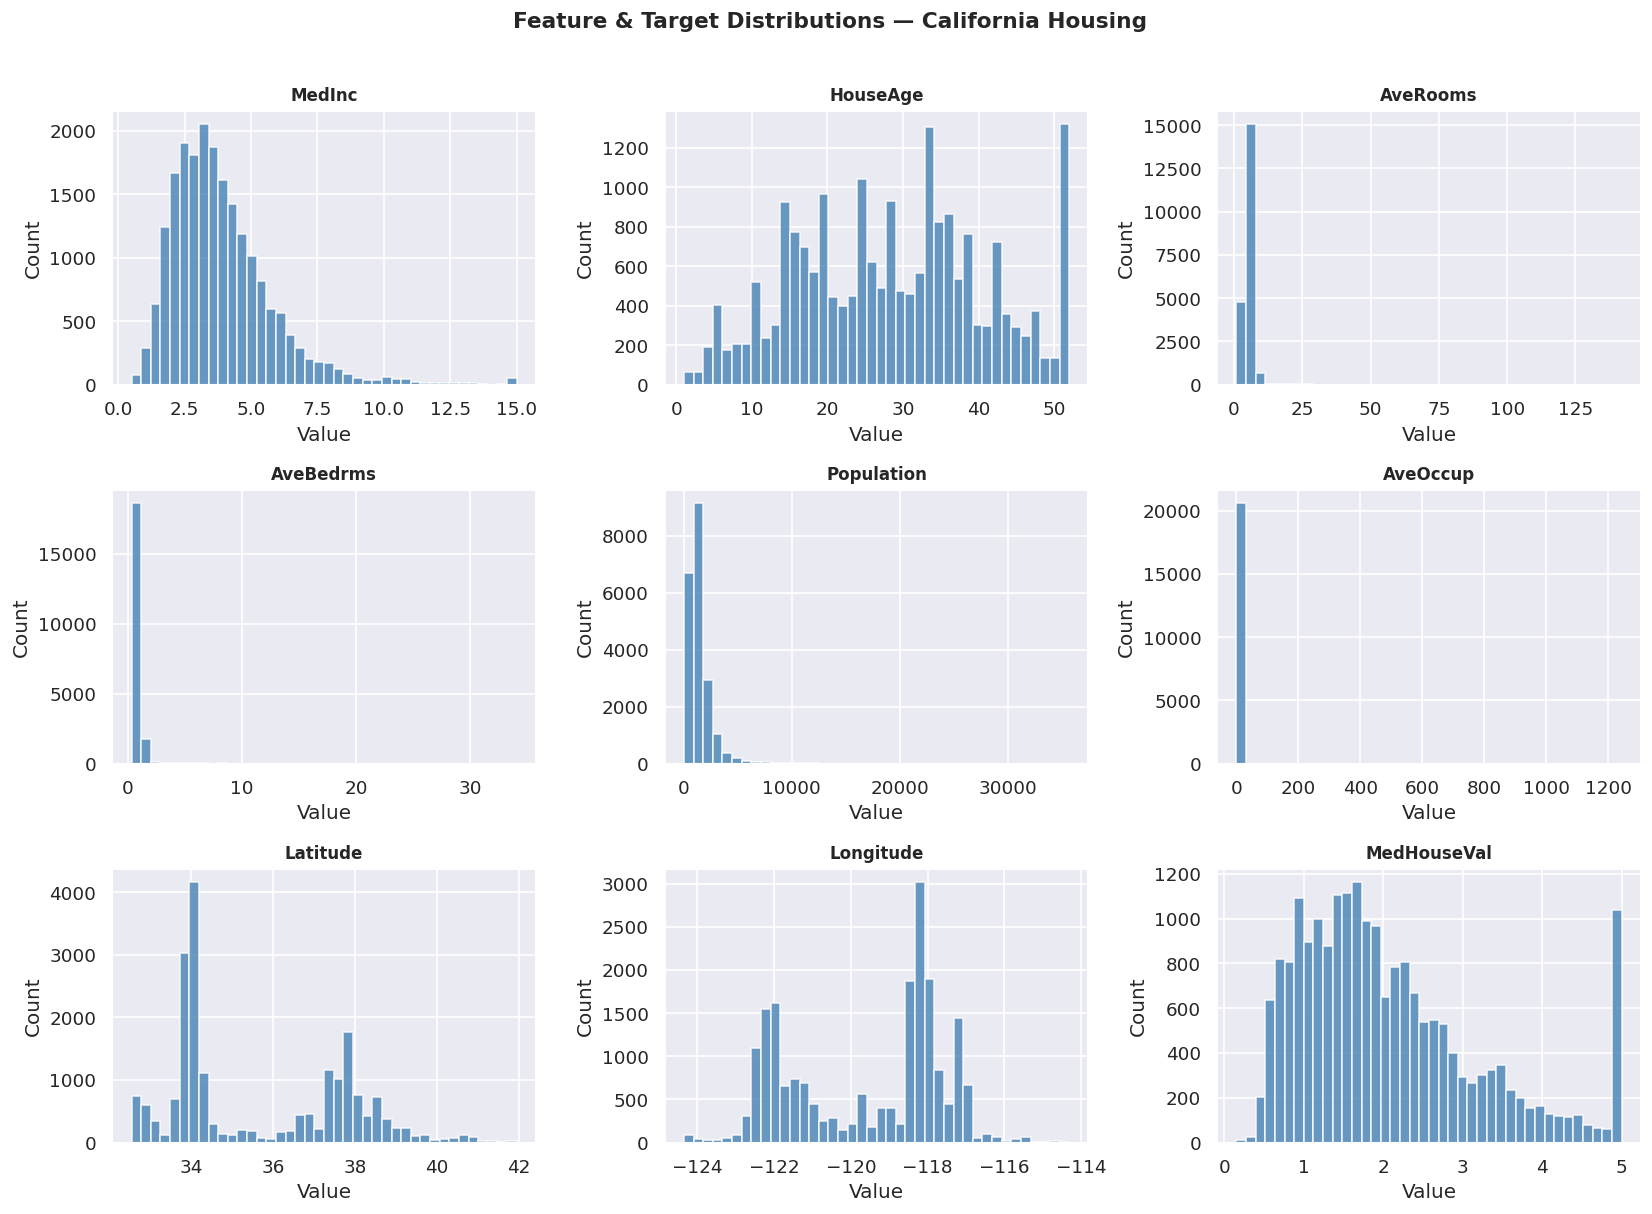


Observation: MedHouseVal is right-skewed with a hard cap at 5.0 ($500k).
This cap introduces outliers that will affect MSE more than MAE/Huber.


In [ ]:
# ── Visualize distributions ────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()
for i, col in enumerate(df.columns):
    axes[i].hist(df[col], bins=40, color='steelblue', edgecolor='white', alpha=0.8)
    axes[i].set_title(col, fontsize=10, fontweight='bold')
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Count')
plt.suptitle('Feature & Target Distributions — California Housing', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print("\nObservation: MedHouseVal is right-skewed with a hard cap at 5.0 ($500k).")
print("This cap introduces outliers that will affect MSE more than MAE/Huber.")

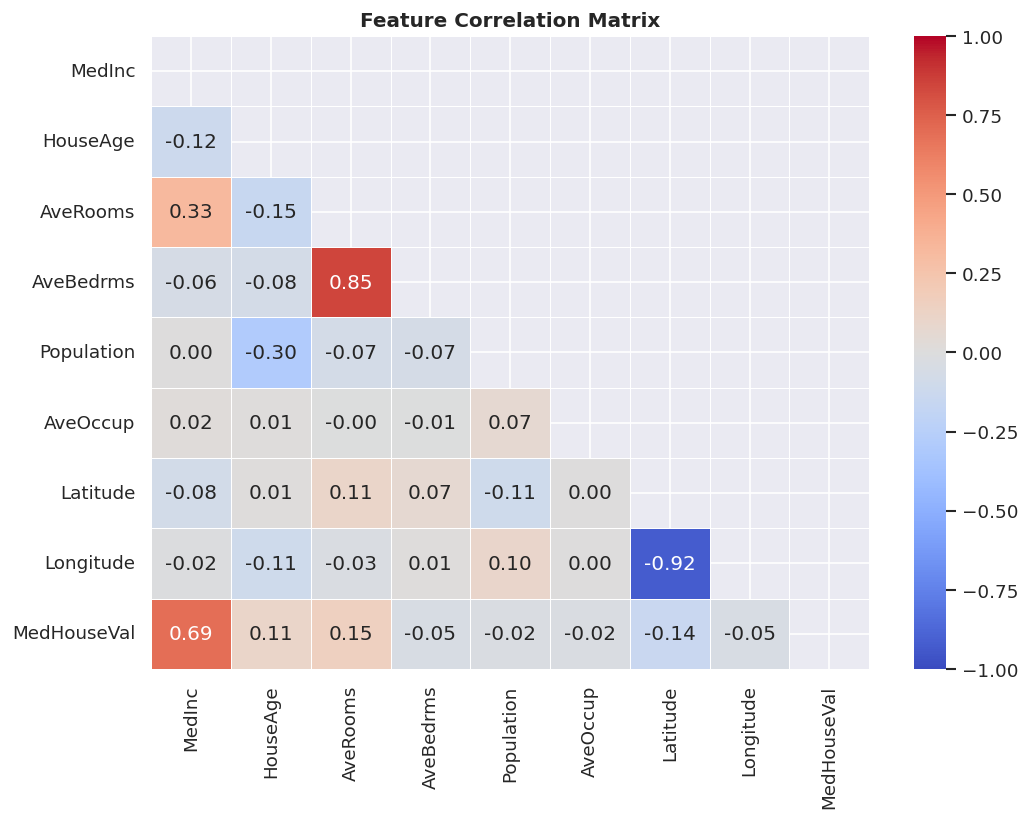

In [ ]:
# ── Correlation heatmap ────────────────────────────────────────────────────────
plt.figure(figsize=(9, 7))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', mask=mask,
            linewidths=0.5, vmin=-1, vmax=1)
plt.title('Feature Correlation Matrix', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# ── Prepare X, y ──────────────────────────────────────────────────────────────
X = df.drop(columns=['MedHouseVal']).values
y = df['MedHouseVal'].values

# Train / Val / Test split  (70 / 15 / 15)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.1765, random_state=42)
# 0.1765 of 0.85 ≈ 0.15 of total

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

# ── Feature Scaling ────────────────────────────────────────────────────────────
# Fit only on training set to avoid data leakage
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

print("\nFeature scaling applied: StandardScaler (zero mean, unit variance)")
print("Justification: Features span very different ranges (e.g., Population ~1000s vs AveRooms ~5).")
print("StandardScaler ensures no single feature dominates gradient updates.")

Train: (14447, 8), Val: (3097, 8), Test: (3096, 8)

Feature scaling applied: StandardScaler (zero mean, unit variance)
Justification: Features span very different ranges (e.g., Population ~1000s vs AveRooms ~5).
StandardScaler ensures no single feature dominates gradient updates.


## 4. MLP Architecture

**Architecture Design:**
- **Input layer:** 8 neurons (one per feature)
- **Hidden layer 1:** 128 neurons
- **Hidden layer 2:** 64 neurons
- **Hidden layer 3:** 32 neurons
- **Output layer:** 1 neuron, **no activation** (regression — linear output)
- **Optimizer:** Adam (lr=0.001) — adaptive, robust default for regression
- **Batch size:** 64
- **Epochs:** Up to 150 with EarlyStopping (patience=15)
- **L2 regularization:** 1e-4 on all hidden layers to reduce overfitting

In [ ]:
INPUT_DIM   = X_train_s.shape[1]
EPOCHS      = 150
BATCH_SIZE  = 64
LR          = 0.001
L2_REG      = 1e-4

def build_model(activation='relu', loss='mse'):
    """Build and compile a 3-hidden-layer MLP for regression."""
    model = keras.Sequential([
        layers.Input(shape=(INPUT_DIM,)),
        layers.Dense(128, activation=activation,
                     kernel_regularizer=regularizers.l2(L2_REG)),
        layers.BatchNormalization(),
        layers.Dense(64, activation=activation,
                     kernel_regularizer=regularizers.l2(L2_REG)),
        layers.BatchNormalization(),
        layers.Dense(32, activation=activation,
                     kernel_regularizer=regularizers.l2(L2_REG)),
        layers.Dense(1)   # linear output — no activation for regression
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LR),
        loss=loss,
        metrics=['mae']
    )
    return model

# Sanity check — print summary for the base model
build_model().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 11,905 (46.50 KB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
def train_model(activation='relu', loss='mse', label=''):
    """Train model and return (history, model)."""
    tf.random.set_seed(42)
    model = build_model(activation=activation, loss=loss)
    es = EarlyStopping(monitor='val_loss', patience=15,
                       restore_best_weights=True, verbose=0)
    history = model.fit(
        X_train_s, y_train,
        validation_data=(X_val_s, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[es],
        verbose=0
    )
    epochs_run = len(history.history['loss'])
    loss_name = loss if isinstance(loss, str) else loss.__class__.__name__
    print(f"  [{label}]  Activation={activation:8s} | Loss={loss_name:12s} | Epochs={epochs_run}")
    return history, model

def evaluate_model(model, label):
    """Return dict of test-set metrics."""
    y_pred = model.predict(X_test_s, verbose=0).flatten()
    mse  = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(y_test, y_pred)
    r2   = r2_score(y_test, y_pred)
    return {'Label': label, 'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'R²': r2}

## 5. Experiment A — Activation Function Comparison

**Fixed:** Loss = MSE (standard baseline for regression)

**Varied:** ReLU | Sigmoid | Tanh

**Justification for each:**
| Activation | Why test it here |
|---|---|
| **ReLU** | Default for regression; avoids vanishing gradients; computationally cheap; good for deep nets |
| **Sigmoid** | Squashes output to (0,1); suffers vanishing gradient in deep layers; useful baseline to show its limitation |
| **Tanh** | Zero-centered output (−1,1); stronger gradient signal than Sigmoid; historically strong for shallow nets |

In [ ]:
print("=== Experiment A: Activation Functions (Loss = MSE) ===")
act_experiments = [
    ('relu',    'mse', 'A1 – ReLU   + MSE'),
    ('sigmoid', 'mse', 'A2 – Sigmoid + MSE'),
    ('tanh',    'mse', 'A3 – Tanh   + MSE'),
]

act_histories = {}
act_models    = {}
act_metrics   = []

for act, loss, label in act_experiments:
    hist, mdl = train_model(activation=act, loss=loss, label=label)
    act_histories[label] = hist
    act_models[label]    = mdl
    m = evaluate_model(mdl, label)
    act_metrics.append(m)
    print(f"    → MAE={m['MAE']:.4f} | RMSE={m['RMSE']:.4f} | R²={m['R²']:.4f}")

=== Experiment A: Activation Functions (Loss = MSE) ===
  [A1 – ReLU   + MSE]  Activation=relu     | Loss=mse          | Epochs=26
    → MAE=0.4230 | RMSE=0.5899 | R²=0.7345
  [A2 – Sigmoid + MSE]  Activation=sigmoid  | Loss=mse          | Epochs=51
    → MAE=0.3564 | RMSE=0.5285 | R²=0.7868
  [A3 – Tanh   + MSE]  Activation=tanh     | Loss=mse          | Epochs=60
    → MAE=0.3626 | RMSE=0.5331 | R²=0.7831


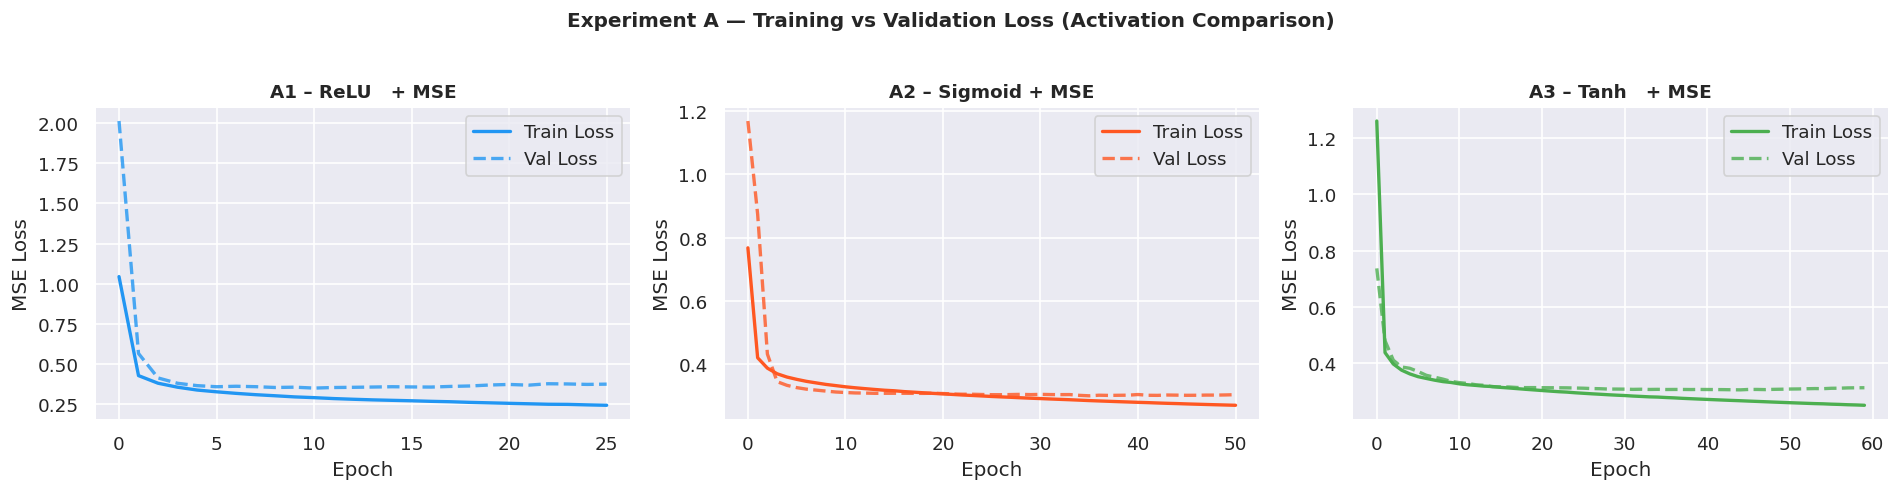

In [ ]:
# ── Loss curves — Activation experiments ──────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=False)
colors = ['#2196F3', '#FF5722', '#4CAF50']

for ax, (label, hist), color in zip(axes, act_histories.items(), colors):
    ax.plot(hist.history['loss'], label='Train Loss', color=color, lw=2)
    ax.plot(hist.history['val_loss'], label='Val Loss', color=color,
            lw=2, linestyle='--', alpha=0.8)
    ax.set_title(label, fontsize=11, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MSE Loss')
    ax.legend()

plt.suptitle('Experiment A — Training vs Validation Loss (Activation Comparison)',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 6. Experiment B — Loss Function Comparison

**Fixed:** Activation = ReLU (the common default for regression, kept constant so only the loss changes)

**Varied:** MSE | MAE | Huber Loss

**Justification for each on California Housing:**
| Loss | Formula (approx) | Why appropriate |
|---|---|---|
| **MSE** | mean(ŷ−y)² | Penalizes large errors heavily; sensitive to the $500k cap outliers; good when outliers matter |
| **MAE** | mean(|ŷ−y|) | Robust to outliers; treats all errors equally; good when capped distribution skews predictions |
| **Huber** | MSE when err<δ, MAE otherwise | Best of both — smooth for small errors, robust for large ones; ideal for skewed regression targets |

In [ ]:
print("=== Experiment B: Loss Functions (Activation = ReLU) ===")

huber = keras.losses.Huber(delta=1.0)  # delta=1.0 is standard

loss_experiments = [
    ('relu', 'mse',           'B1 – ReLU + MSE'),
    ('relu', 'mae',           'B2 – ReLU + MAE'),
    ('relu', huber,           'B3 – ReLU + Huber'),
]

loss_histories = {}
loss_models    = {}
loss_metrics   = []

for act, loss, label in loss_experiments:
    hist, mdl = train_model(activation=act, loss=loss, label=label)
    loss_histories[label] = hist
    loss_models[label]    = mdl
    m = evaluate_model(mdl, label)
    loss_metrics.append(m)
    print(f"    → MAE={m['MAE']:.4f} | RMSE={m['RMSE']:.4f} | R²={m['R²']:.4f}")

=== Experiment B: Loss Functions (Activation = ReLU) ===
  [B1 – ReLU + MSE]  Activation=relu     | Loss=mse          | Epochs=26
    → MAE=0.4146 | RMSE=0.5713 | R²=0.7509
  [B2 – ReLU + MAE]  Activation=relu     | Loss=mae          | Epochs=36
    → MAE=0.3941 | RMSE=0.5665 | R²=0.7552
  [B3 – ReLU + Huber]  Activation=relu     | Loss=Huber        | Epochs=31
    → MAE=0.4284 | RMSE=0.5918 | R²=0.7327


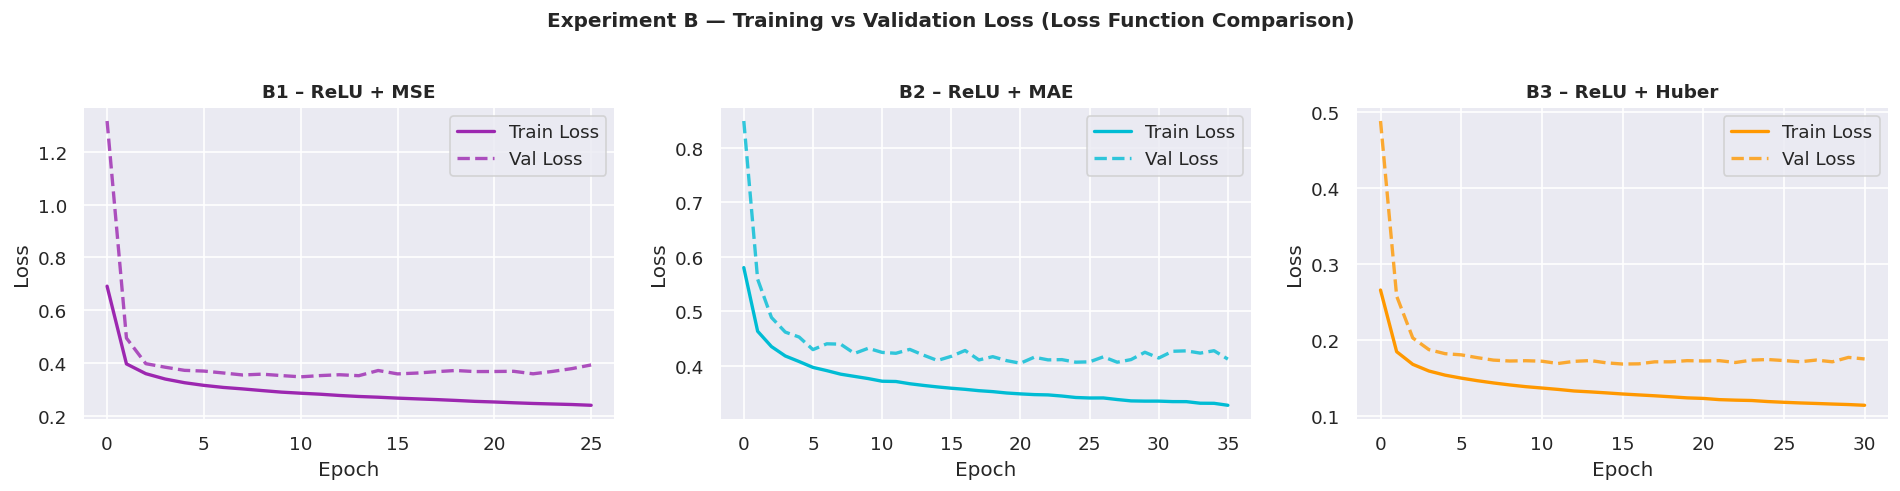

In [ ]:
# ── Loss curves — Loss function experiments ────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
colors = ['#9C27B0', '#00BCD4', '#FF9800']

for ax, (label, hist), color in zip(axes, loss_histories.items(), colors):
    ax.plot(hist.history['loss'], label='Train Loss', color=color, lw=2)
    ax.plot(hist.history['val_loss'], label='Val Loss', color=color,
            lw=2, linestyle='--', alpha=0.8)
    ax.set_title(label, fontsize=11, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.legend()

plt.suptitle('Experiment B — Training vs Validation Loss (Loss Function Comparison)',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 7. Model Evaluation — All Experiments

In [ ]:
# Combine all unique experiments
# B1 (ReLU + MSE) is the same as A1, so we deduplicate
all_metrics = act_metrics + loss_metrics[1:]  # skip B1 (duplicate of A1)

results_df = pd.DataFrame(all_metrics).set_index('Label')
results_df = results_df.round(4)
results_df['Activation'] = [
    'ReLU', 'Sigmoid', 'Tanh', 'ReLU', 'ReLU'
]
results_df['Loss Function'] = [
    'MSE', 'MSE', 'MSE', 'MAE', 'Huber'
]
results_df = results_df[['Activation', 'Loss Function', 'MAE', 'RMSE', 'R²']]

print("=== Full Comparison Table ===")
print(results_df.to_string())
results_df

=== Full Comparison Table ===
                   Activation Loss Function     MAE    RMSE      R²
Label                                                              
A1 – ReLU   + MSE        ReLU           MSE  0.4230  0.5899  0.7345
A2 – Sigmoid + MSE    Sigmoid           MSE  0.3564  0.5285  0.7868
A3 – Tanh   + MSE        Tanh           MSE  0.3626  0.5331  0.7831
B2 – ReLU + MAE          ReLU           MAE  0.3941  0.5665  0.7552
B3 – ReLU + Huber        ReLU         Huber  0.4284  0.5918  0.7327


,Activation,Loss Function,MAE,RMSE,R²
Label,,,,,
A1 – ReLU + MSE,ReLU,MSE,0.4230,0.5899,0.7345
A2 – Sigmoid + MSE,Sigmoid,MSE,0.3564,0.5285,0.7868
A3 – Tanh + MSE,Tanh,MSE,0.3626,0.5331,0.7831
B2 – ReLU + MAE,ReLU,MAE,0.3941,0.5665,0.7552
B3 – ReLU + Huber,ReLU,Huber,0.4284,0.5918,0.7327


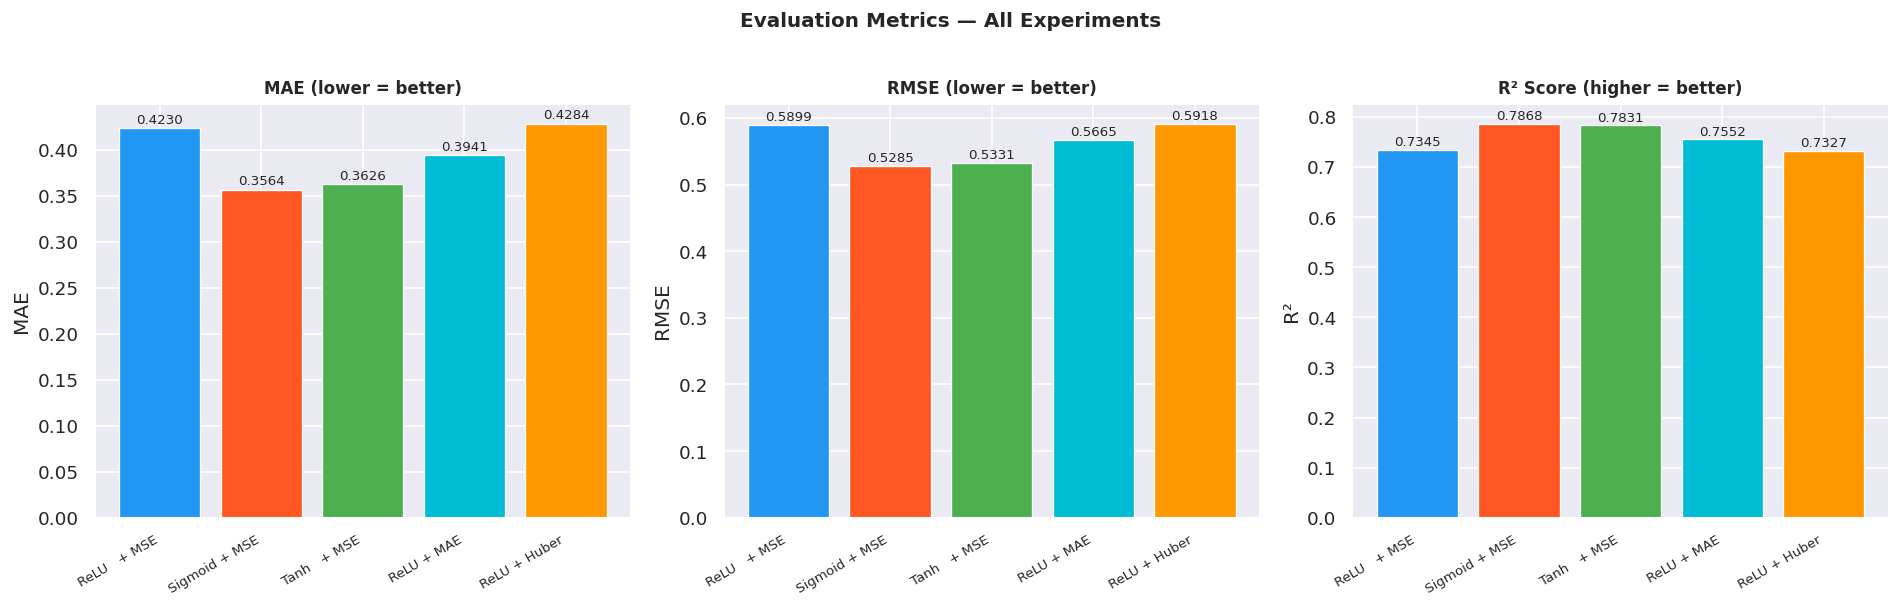

In [ ]:
# ── Metric bar charts ──────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
labels    = results_df.index.tolist()
x         = np.arange(len(labels))
palette   = ['#2196F3', '#FF5722', '#4CAF50', '#00BCD4', '#FF9800']

for ax, metric, title in zip(axes,
                              ['MAE', 'RMSE', 'R²'],
                              ['MAE (lower = better)',
                               'RMSE (lower = better)',
                               'R² Score (higher = better)']):
    bars = ax.bar(x, results_df[metric], color=palette, edgecolor='white', linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels([l.split(' – ')[1] for l in labels], rotation=30, ha='right', fontsize=8)
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.set_ylabel(metric)
    for bar, val in zip(bars, results_df[metric]):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.002,
                f'{val:.4f}', ha='center', va='bottom', fontsize=8)

plt.suptitle('Evaluation Metrics — All Experiments', fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

Best model by R²: A2 – Sigmoid + MSE


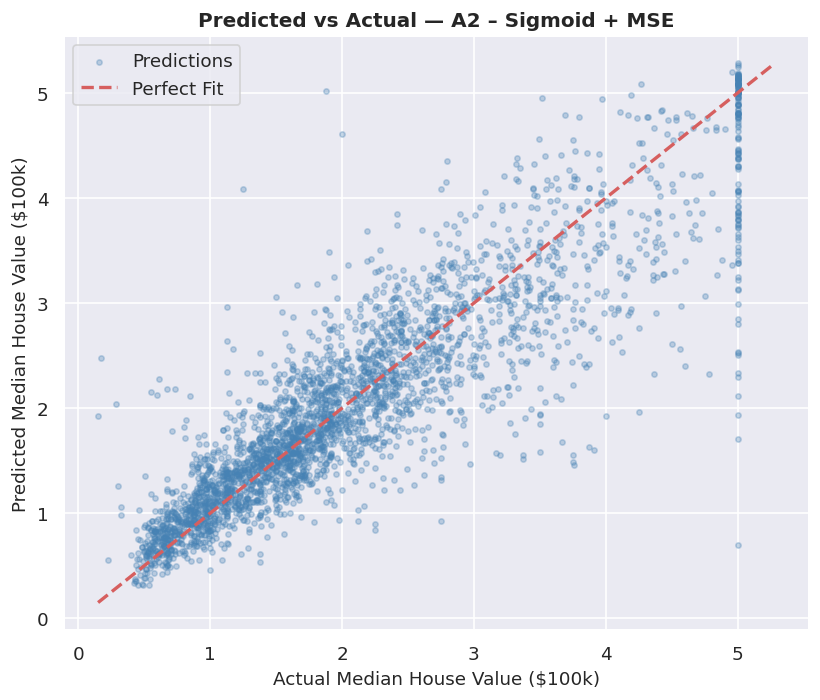

In [ ]:
# ── Predicted vs Actual — Best model ──────────────────────────────────────────
# Identify best model by R²
best_label = results_df['R²'].idxmax()
print(f"Best model by R²: {best_label}")

# Retrieve the corresponding model object
all_model_dicts = {**act_models, **loss_models}
best_model = all_model_dicts[best_label]

y_pred_best = best_model.predict(X_test_s, verbose=0).flatten()

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_best, alpha=0.3, s=10, color='steelblue', label='Predictions')
lims = [min(y_test.min(), y_pred_best.min()),
        max(y_test.max(), y_pred_best.max())]
plt.plot(lims, lims, 'r--', lw=2, label='Perfect Fit')
plt.xlabel('Actual Median House Value ($100k)', fontsize=11)
plt.ylabel('Predicted Median House Value ($100k)', fontsize=11)
plt.title(f'Predicted vs Actual — {best_label}', fontsize=12, fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

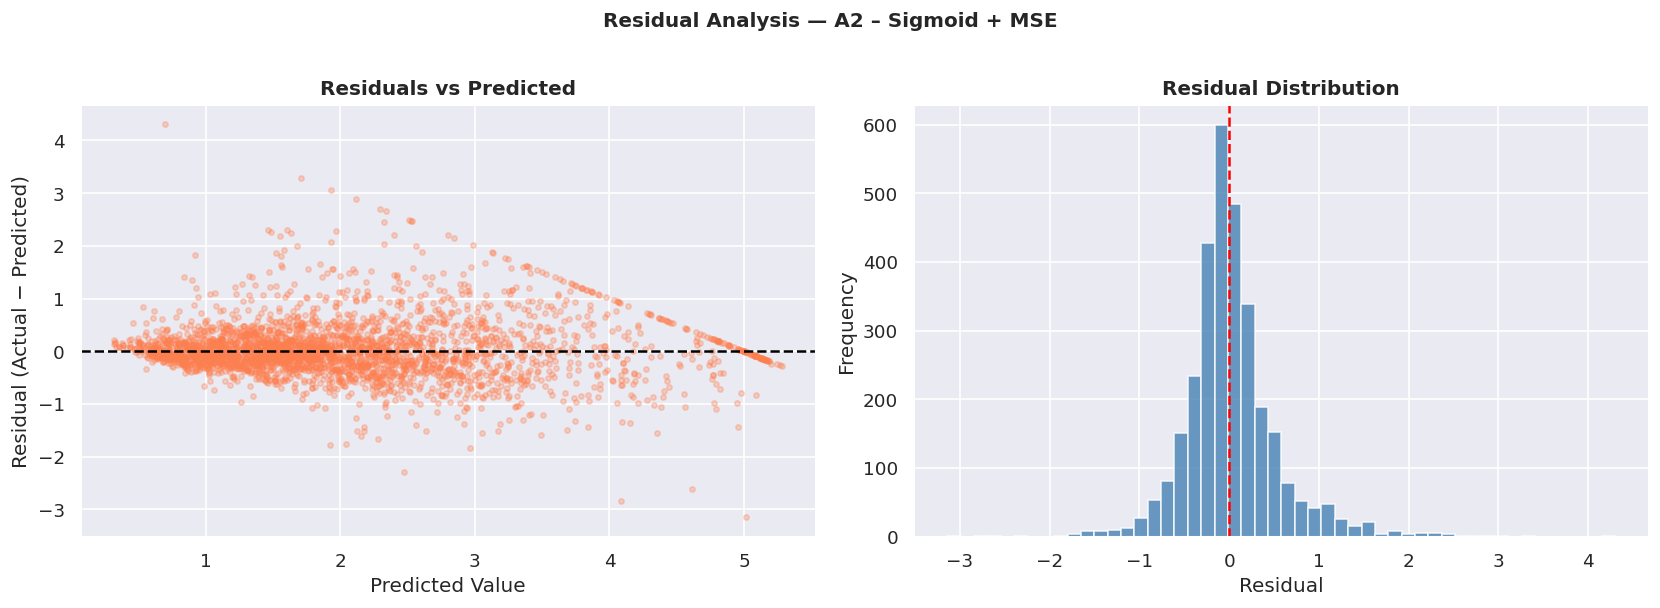

In [ ]:
# ── Residual plot — Best model ─────────────────────────────────────────────────
residuals = y_test - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_pred_best, residuals, alpha=0.3, s=10, color='coral')
axes[0].axhline(0, color='black', lw=1.5, linestyle='--')
axes[0].set_xlabel('Predicted Value')
axes[0].set_ylabel('Residual (Actual − Predicted)')
axes[0].set_title('Residuals vs Predicted', fontweight='bold')

axes[1].hist(residuals, bins=50, color='steelblue', edgecolor='white', alpha=0.8)
axes[1].axvline(0, color='red', lw=1.5, linestyle='--')
axes[1].set_xlabel('Residual')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Residual Distribution', fontweight='bold')

plt.suptitle(f'Residual Analysis — {best_label}', fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 8. Comparison Table

In [ ]:
# Pretty-print comparison table
from IPython.display import display, HTML

styled = results_df.style \
    .highlight_min(subset=['MAE', 'RMSE'], color='#c8e6c9') \
    .highlight_max(subset=['R²'], color='#c8e6c9') \
    .highlight_max(subset=['MAE', 'RMSE'], color='#ffcdd2') \
    .highlight_min(subset=['R²'], color='#ffcdd2') \
    .set_caption('Model Comparison Table (Green = Best, Red = Worst per metric)') \
    .format({'MAE': '{:.4f}', 'RMSE': '{:.4f}', 'R²': '{:.4f}'})

display(styled)

,Activation,Loss Function,MAE,RMSE,R²
Label,,,,,
A1 – ReLU + MSE,ReLU,MSE,0.4230,0.5899,0.7345
A2 – Sigmoid + MSE,Sigmoid,MSE,0.3564,0.5285,0.7868
A3 – Tanh + MSE,Tanh,MSE,0.3626,0.5331,0.7831
B2 – ReLU + MAE,ReLU,MAE,0.3941,0.5665,0.7552
B3 – ReLU + Huber,ReLU,Huber,0.4284,0.5918,0.7327


## 9. Analysis and Interpretation

Results used below (test set): Sigmoid + MSE R2 0.7868, Tanh + MSE 0.7831, ReLU + MAE 0.7552, ReLU + MSE 0.7345 (a second ReLU + MSE run scored 0.7509), ReLU + Huber 0.7327. Each setting was run once with the same seed, so small gaps can be noise.

### 9.1 Which Activation Function Performed Best?

**Sigmoid** performed best, with the lowest MAE (0.3564), the lowest RMSE (0.5285) and the highest R2 (0.7868). **Tanh** was very close behind (R2 0.7831). **ReLU** was clearly last (R2 0.7345).

This is the opposite of the usual expectation that ReLU wins. Likely reasons:

- The network is small (three hidden layers) and uses **BatchNorm** and L2 regularisation, so the vanishing gradient problem that normally hurts Sigmoid is not a serious issue here.
- House prices change smoothly with income and location, which suits a smooth, bounded activation.
- The ReLU runs stopped early (26 epochs) while Sigmoid and Tanh trained for 51 and 60 epochs, so ReLU may have stopped at a worse point on a noisy validation curve.

Tanh is zero-centered (output in (-1, 1)), which usually gives better gradient flow than Sigmoid, but here the two ended up almost level.

### 9.2 Which Loss Function Performed Best?

With ReLU fixed, **MAE** was best (R2 0.7552, MAE 0.3941), then **MSE** (R2 0.7345 and 0.7509 in two runs), and **Huber** was weakest (R2 0.7327, MAE 0.4284).

- **MSE** squares errors, so the districts capped at $500k (5.0) pull predictions toward them and push RMSE up.
- **MAE** treats every error equally, so those capped districts have less pull. That fits the small improvement seen.
- **Huber** (delta = 1.0) behaves like MSE for errors below 1.0. Most errors here are below 1.0 (the RMSE of every model is around 0.55), so Huber acted almost like MSE and did not get the outlier robustness it is known for. A smaller delta might change that.

The gap between MAE and MSE is small and the two ReLU + MSE runs differ by about 0.016 R2, so the loss ranking is weaker evidence than the activation result.

### 9.3 Best Combination

**Sigmoid + MSE** (test MAE 0.3564, RMSE 0.5285, R2 0.7868). It is the best of the five runs on every metric. The Sigmoid + MAE and Tanh + MAE combinations were not tested, so the notebook cannot say whether they would do better.

### 9.4 Effect of Activation Function on Convergence

Yes, it changed how long training ran. ReLU stopped at 26 epochs, Sigmoid at 51 and Tanh at 60 (early stopping, patience 15). Faster stopping did not mean a better result: the ReLU models finished with the highest error. Check the loss curves above to see how smooth each one was.

### 9.5 Loss Function Robustness to Outliers

MAE was the most robust of the three here, because it does not square the large errors from the $500k-capped districts (about 5% of the data). Huber did not show the expected advantage with delta = 1.0, for the reason in 9.2.

### 9.6 Overfitting / Underfitting Analysis

- **All models:** EarlyStopping with restore_best_weights stopped each run once validation loss stopped improving, and L2 plus BatchNorm add regularisation. That limits overfitting.
- **How to read the curves:** a small, steady gap between training and validation loss means a healthy fit. A high loss on both means underfitting. Use the curve plots above to judge each run, since the gap sizes are not printed.
- **ReLU runs:** they stopped earliest and scored worst on the test set, which could mean they underfit or that validation loss was noisy and triggered early stopping too soon. More seeds or a longer patience would show which.

## 10. Final Model Selection

In [ ]:
print("=" * 55)
print("        FINAL MODEL SELECTION SUMMARY")
print("=" * 55)
print()
best_row = results_df.loc[best_label]
print(f"  Selected Model  : {best_label}")
print(f"  Activation      : {best_row['Activation']}")
print(f"  Loss Function   : {best_row['Loss Function']}")
print(f"  Architecture    : 8 → 128 → 64 → 32 → 1 (linear)")
print(f"  Optimizer       : Adam (lr=0.001)")
print()
print(f"  Test MAE        : {best_row['MAE']:.4f}  ($100k)")
print(f"  Test RMSE       : {best_row['RMSE']:.4f}  ($100k)")
print(f"  Test R²         : {best_row['R²']:.4f}")
print()
print("  Justification:")
print("  Sigmoid + MSE had the best test MAE, RMSE and R² of all")
print("  five runs. A smooth, bounded activation suits this small")
print("  network (BatchNorm + L2) and a target that changes")
print("  smoothly with its inputs. ReLU runs stopped earlier and")
print("  finished with higher error. One seed per run, so the gap")
print("  over Tanh is small; the gap over ReLU is not.")
print("=" * 55)

        FINAL MODEL SELECTION SUMMARY

  Selected Model  : A2 – Sigmoid + MSE
  Activation      : Sigmoid
  Loss Function   : MSE
  Architecture    : 8 → 128 → 64 → 32 → 1 (linear)
  Optimizer       : Adam (lr=0.001)

  Test MAE        : 0.3564  ($100k)
  Test RMSE       : 0.5285  ($100k)
  Test R²         : 0.7868

  Justification:
  Sigmoid + MSE had the best test MAE, RMSE and R² of all
  five runs. A smooth, bounded activation suits this small
  network (BatchNorm + L2) and a target that changes
  smoothly with its inputs. ReLU runs stopped earlier and
  finished with higher error. One seed per run, so the gap
  over Tanh is small; the gap over ReLU is not.
